# Predicting EV Charging Station Demand using the KDD Process
**Predictive Analytics — CA3**

## Problem Statement
EV charging companies need to know how busy a new station will be before they build it.

**Goal:** predict the **average number of users per day** at a charging station from its features (charger type, cost, location, capacity, parking, and so on).

- **Target:** `Usage Stats (avg users/day)`
- **Type of problem:** Regression (predicting a number)

**KDD steps followed:**
1. Data Selection
2. Data Pre-processing
3. Data Transformation
4. Data Mining (Modelling)
5. Evaluation and Interpretation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

## Step 1: Data Selection
Dataset: **Detailed EV Charging Stations** (Kaggle). It has 5,000 stations and 17 columns.

In [2]:
df = pd.read_csv("detailed_ev_charging_stations.csv")
print("Shape:", df.shape)
df.head()

Shape: (5000, 17)


,Station ID,Latitude,Longitude,Address,Charger Type,Cost (USD/kWh),Availability,Distance to City (km),Usage Stats (avg users/day),Station Operator,Charging Capacity (kW),Connector Types,Installation Year,Renewable Energy Source,Reviews (Rating),Parking Spots,Maintenance Frequency
0,EVS00001,-33.400998,77.974972,"4826 Random Rd, City 98, Country",AC Level 2,0.27,9:00-18:00,4.95,35,EVgo,350,"CCS, CHAdeMO",2013,Yes,4.0,7,Annually
1,EVS00002,37.861857,-122.490299,"8970 San Francisco Ave, San Francisco",DC Fast Charger,0.19,24/7,4.96,83,EVgo,350,"Tesla, Type 2",2010,Yes,3.9,2,Monthly
2,EVS00003,13.776092,100.412776,"5974 Bangkok Ave, Bangkok",AC Level 2,0.48,6:00-22:00,8.54,24,ChargePoint,50,"Type 2, CCS",2019,No,3.6,9,Annually
3,EVS00004,43.628250,-79.468935,"6995 Toronto Ave, Toronto",AC Level 1,0.41,9:00-18:00,13.28,70,Greenlots,350,Type 2,2010,Yes,4.2,7,Monthly
4,EVS00005,19.119865,72.913368,"5704 Mumbai Ave, Mumbai",AC Level 2,0.11,9:00-18:00,9.76,19,EVgo,350,CCS,2015,Yes,3.7,6,Annually


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Station ID                   5000 non-null   str    
 1   Latitude                     5000 non-null   float64
 2   Longitude                    5000 non-null   float64
 3   Address                      5000 non-null   str    
 4   Charger Type                 5000 non-null   str    
 5   Cost (USD/kWh)               5000 non-null   float64
 6   Availability                 5000 non-null   str    
 7   Distance to City (km)        5000 non-null   float64
 8   Usage Stats (avg users/day)  5000 non-null   int64  
 9   Station Operator             5000 non-null   str    
 10  Charging Capacity (kW)       5000 non-null   int64  
 11  Connector Types              5000 non-null   str    
 12  Installation Year            5000 non-null   int64  
 13  Renewable Energy Source      

In [4]:
df.describe()

,Latitude,Longitude,Cost (USD/kWh),Distance to City (km),Usage Stats (avg users/day),Charging Capacity (kW),Installation Year,Reviews (Rating),Parking Spots
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,19.942607,8.833487,0.300196,10.201810,55.453800,144.272000,2016.569400,3.994800,5.519600
std,32.315818,93.724046,0.115733,5.608316,26.494986,128.370674,4.004746,0.582667,2.874103
min,-89.680850,-178.870028,0.100000,0.500000,10.000000,22.000000,2010.000000,3.000000,1.000000
25%,13.758953,-87.680319,0.200000,5.430000,32.000000,50.000000,2013.000000,3.500000,3.000000
50%,34.029053,18.495233,0.300000,10.190000,56.000000,150.000000,2017.000000,4.000000,5.000000
75%,41.840249,100.454629,0.400000,14.902500,79.000000,350.000000,2020.000000,4.500000,8.000000
max,89.464534,179.664661,0.500000,20.000000,100.000000,350.000000,2023.000000,5.000000,10.000000


## Step 2: Data Pre-processing
### 2.1 Missing values and duplicates

In [5]:
print("Missing values in each column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values in each column:
Station ID                     0
Latitude                       0
Longitude                      0
Address                        0
Charger Type                   0
Cost (USD/kWh)                 0
Availability                   0
Distance to City (km)          0
Usage Stats (avg users/day)    0
Station Operator               0
Charging Capacity (kW)         0
Connector Types                0
Installation Year              0
Renewable Energy Source        0
Reviews (Rating)               0
Parking Spots                  0
Maintenance Frequency          0
dtype: int64

Duplicate rows: 0


There are no missing values and no duplicate rows, so no cleaning is needed here.

### 2.2 Outliers

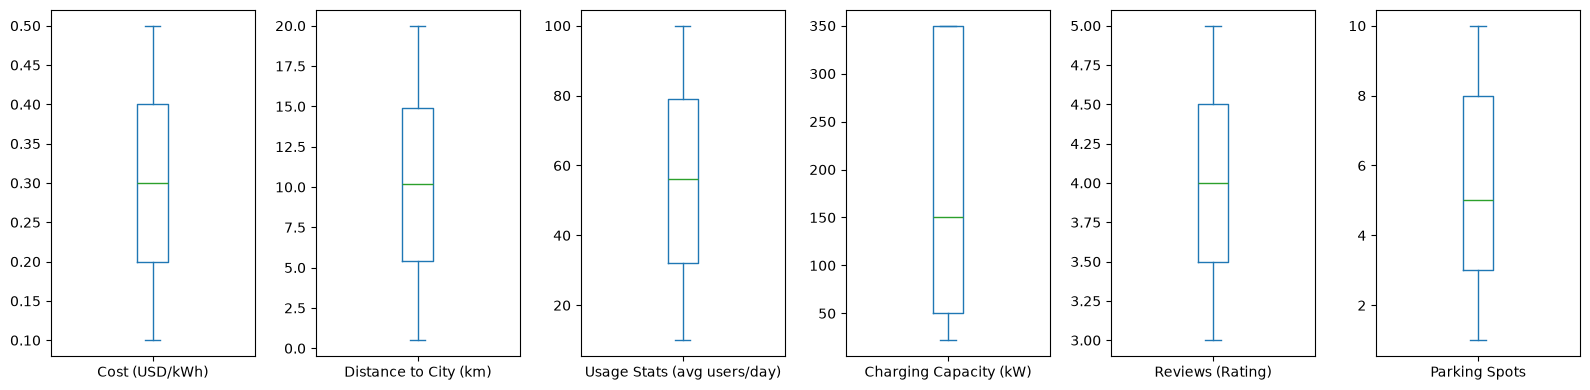

In [6]:
num_cols = ["Cost (USD/kWh)", "Distance to City (km)", "Usage Stats (avg users/day)",
            "Charging Capacity (kW)", "Reviews (Rating)", "Parking Spots"]

df[num_cols].plot(kind="box", subplots=True, layout=(1, 6), figsize=(16, 4))
plt.tight_layout()
plt.show()

The box plots show no extreme outliers. All values are in sensible ranges.

### 2.3 Data quality check
In real life, AC Level 1 chargers are slow (about 2 kW) and DC Fast Chargers are fast (50–350 kW). Let's check whether the data agrees.

In [7]:
pd.crosstab(df["Charger Type"], df["Charging Capacity (kW)"])

Charging Capacity (kW),22,50,150,350
Charger Type,,,,
AC Level 1,401,384,418,435
AC Level 2,406,479,431,448
DC Fast Charger,398,393,434,373


In [8]:
df.groupby("Charger Type")["Cost (USD/kWh)"].mean()

Charger Type
AC Level 1         0.299890
AC Level 2         0.298844
DC Fast Charger    0.302003
Name: Cost (USD/kWh), dtype: float64

**Observation:** every charger type appears with every capacity (even AC Level 1 at 350 kW, which is impossible), and all charger types have the same average cost. Some addresses are also placeholders such as "Random Rd, City 98, Country". This suggests the dataset is **synthetic (randomly generated)**, which may limit how well any model can predict.

### 2.4 Exploratory Data Analysis (EDA)

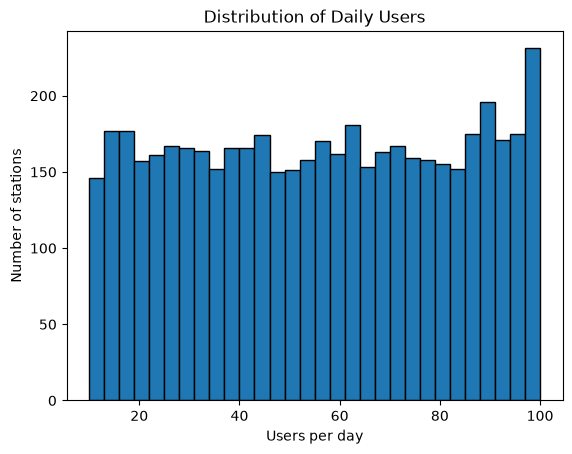

In [9]:
target = "Usage Stats (avg users/day)"

plt.hist(df[target], bins=30, edgecolor="black")
plt.title("Distribution of Daily Users")
plt.xlabel("Users per day")
plt.ylabel("Number of stations")
plt.show()

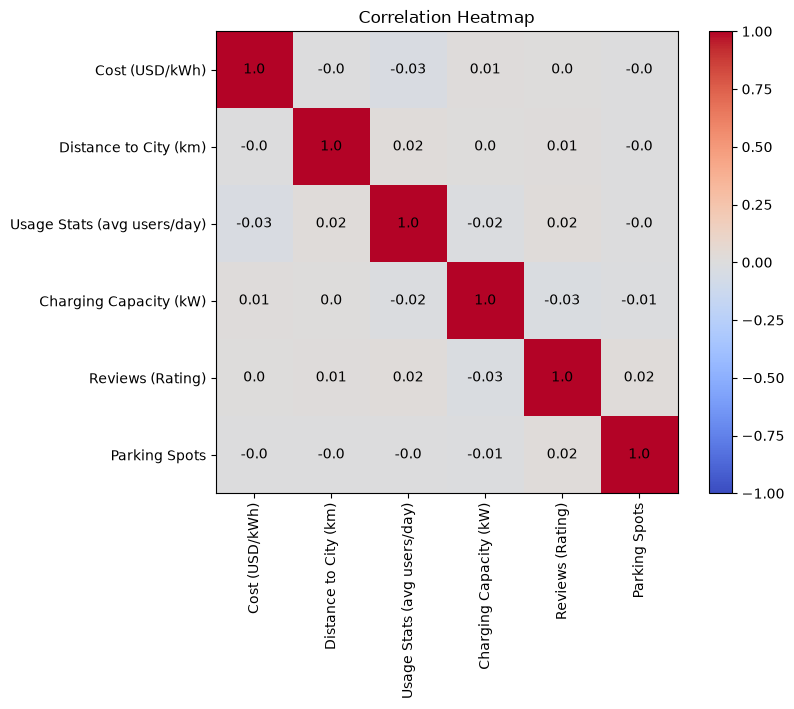

In [10]:
corr = df[num_cols].corr()

plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, round(corr.iloc[i, j], 2), ha="center", va="center")
plt.title("Correlation Heatmap")
plt.show()

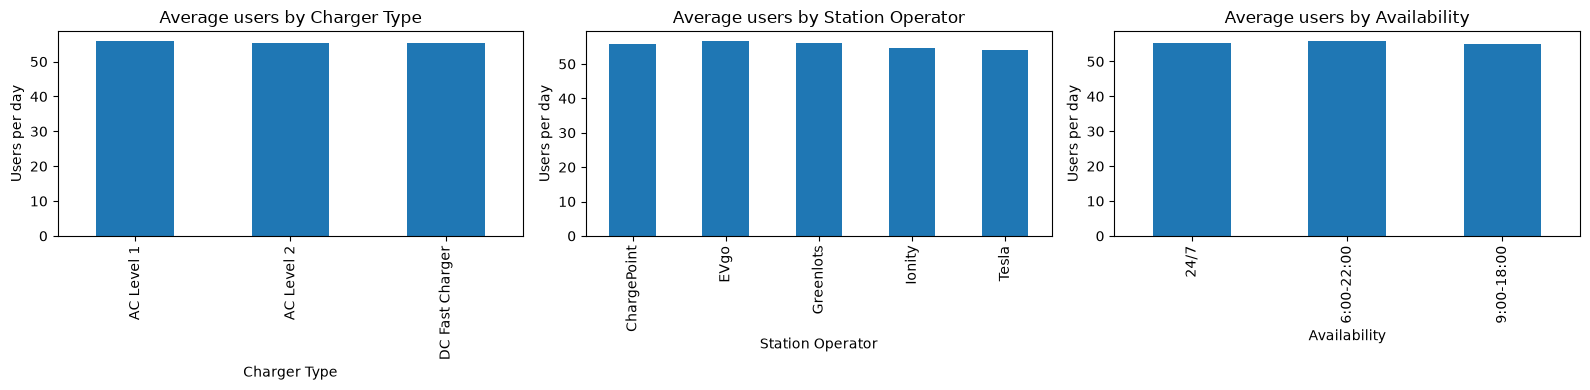

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Charger Type", "Station Operator", "Availability"]):
    df.groupby(col)[target].mean().plot(kind="bar", ax=ax)
    ax.set_title("Average users by " + col)
    ax.set_ylabel("Users per day")
plt.tight_layout()
plt.show()

**EDA findings:**
- Daily users are spread evenly between 10 and 100.
- All correlations with the target are close to 0.
- Average usage is almost the same for every charger type, operator and opening-hours option.

So the features do not seem to have a strong relationship with usage.

## Step 3: Data Transformation
- Drop columns that are not useful: `Station ID` and `Address` (unique text), and `Latitude`/`Longitude`.
- Create a new feature **Station Age** from the installation year.
- Convert text columns into numbers with **one-hot encoding**.
- Split into **train (80%)** and **test (20%)**.
- **Scale** the features with StandardScaler (needed for KNN).

In [12]:
data = df.drop(columns=["Station ID", "Address", "Latitude", "Longitude"])

data["Station Age"] = 2025 - data["Installation Year"]
data = data.drop(columns=["Installation Year"])

data = pd.get_dummies(data, columns=["Charger Type", "Availability", "Station Operator",
                                     "Connector Types", "Renewable Energy Source",
                                     "Maintenance Frequency"], drop_first=True)
print("Shape after encoding:", data.shape)
data.head()

Shape after encoding: (5000, 33)


,Cost (USD/kWh),Distance to City (km),Usage Stats (avg users/day),Charging Capacity (kW),Reviews (Rating),Parking Spots,Station Age,Charger Type_AC Level 2,Charger Type_DC Fast Charger,Availability_6:00-22:00,...,"Connector Types_Tesla, CCS","Connector Types_Tesla, CHAdeMO","Connector Types_Tesla, Type 2",Connector Types_Type 2,"Connector Types_Type 2, CCS","Connector Types_Type 2, CHAdeMO","Connector Types_Type 2, Tesla",Renewable Energy Source_Yes,Maintenance Frequency_Monthly,Maintenance Frequency_Quarterly
0,0.27,4.95,35,350,4.0,7,12,True,False,False,...,False,False,False,False,False,False,False,True,False,False
1,0.19,4.96,83,350,3.9,2,15,False,True,False,...,False,False,True,False,False,False,False,True,True,False
2,0.48,8.54,24,50,3.6,9,6,True,False,True,...,False,False,False,False,True,False,False,False,False,False
3,0.41,13.28,70,350,4.2,7,15,False,False,False,...,False,False,False,True,False,False,False,True,True,False
4,0.11,9.76,19,350,3.7,6,10,True,False,False,...,False,False,False,False,False,False,False,True,False,False


In [13]:
X = data.drop(columns=[target])
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training rows:", X_train.shape[0])
print("Testing rows :", X_test.shape[0])

Training rows: 4000
Testing rows : 1000


## Step 4: Data Mining (Modelling)
We train 4 regression models and compare them:
1. **Linear Regression**: a simple straight-line model
2. **K-Nearest Neighbours (KNN)**: predicts from similar stations
3. **Decision Tree**: learns if/else rules
4. **Random Forest**: many decision trees combined

We also use a **baseline** that always predicts the average usage. A good model must beat this baseline.

In [14]:
models = {
    "Linear Regression": LinearRegression(),
    "KNN": KNeighborsRegressor(n_neighbors=15),
    "Decision Tree": DecisionTreeRegressor(max_depth=5, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=8, random_state=42),
}

results = []

# baseline: always predict the average of the training data
baseline_pred = np.full(len(y_test), y_train.mean())
results.append(["Baseline (mean)",
                r2_score(y_test, baseline_pred),
                mean_absolute_error(y_test, baseline_pred),
                np.sqrt(mean_squared_error(y_test, baseline_pred))])

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    results.append([name,
                    r2_score(y_test, pred),
                    mean_absolute_error(y_test, pred),
                    np.sqrt(mean_squared_error(y_test, pred))])

results_df = pd.DataFrame(results, columns=["Model", "R2", "MAE", "RMSE"]).round(4)
results_df

,Model,R2,MAE,RMSE
0,Baseline (mean),-0.0012,22.8104,26.4311
1,Linear Regression,-0.0016,22.8103,26.4367
2,KNN,-0.0402,23.0293,26.9403
3,Decision Tree,-0.0335,22.9509,26.8542
4,Random Forest,-0.0003,22.7471,26.4185


## Step 5: Evaluation and Interpretation
### 5.1 Comparing the models
- **R²**: 1 is perfect, 0 is no better than predicting the average
- **MAE / RMSE**: average error in users per day (lower is better)

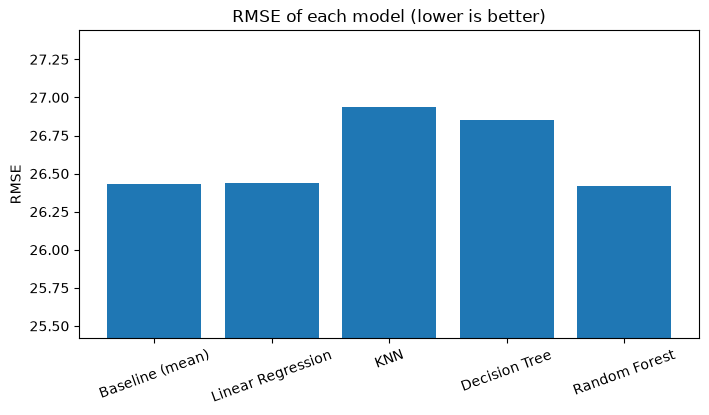

In [15]:
plt.figure(figsize=(8, 4))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.ylim(results_df["RMSE"].min() - 1, results_df["RMSE"].max() + 0.5)
plt.title("RMSE of each model (lower is better)")
plt.ylabel("RMSE")
plt.xticks(rotation=20)
plt.show()

### 5.2 Actual vs predicted (Random Forest)

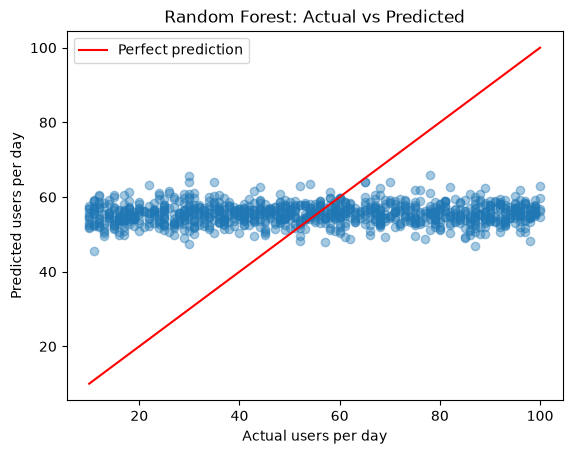

In [16]:
rf = models["Random Forest"]
rf_pred = rf.predict(X_test_scaled)

plt.scatter(y_test, rf_pred, alpha=0.4)
plt.plot([10, 100], [10, 100], color="red", label="Perfect prediction")
plt.xlabel("Actual users per day")
plt.ylabel("Predicted users per day")
plt.title("Random Forest: Actual vs Predicted")
plt.legend()
plt.show()

### 5.3 Feature importance

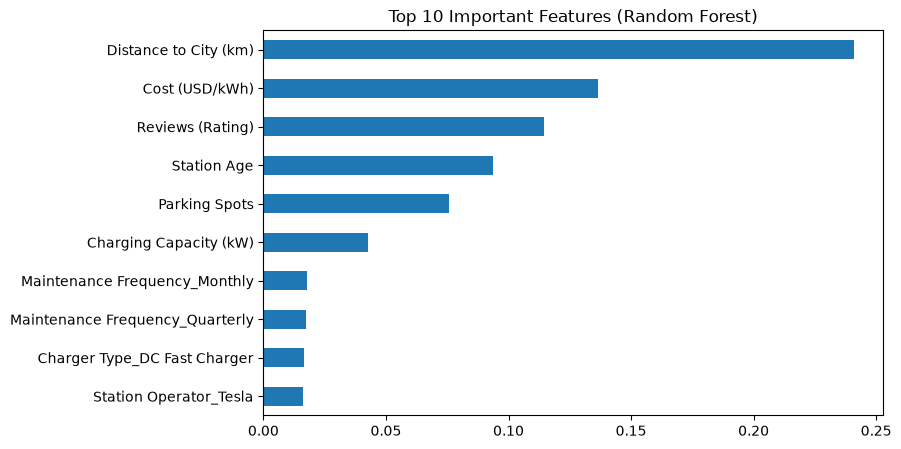

In [17]:
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

importance.head(10).plot(kind="barh", figsize=(8, 5))
plt.gca().invert_yaxis()
plt.title("Top 10 Important Features (Random Forest)")
plt.show()

## Conclusion

**Results:**

| Model | R² | MAE | RMSE |
|---|---|---|---|
| Baseline (mean) | -0.001 | 22.81 | 26.43 |
| Linear Regression | -0.002 | 22.81 | 26.44 |
| KNN | -0.040 | 23.03 | 26.94 |
| Decision Tree | -0.034 | 22.95 | 26.85 |
| **Random Forest** | **-0.000** | **22.75** | **26.42** |

**Findings:**
1. **Random Forest** did best, but only barely: its error is almost the same as simply predicting the average (about 55 users/day).
2. All R² values are about 0, so **none of the features can predict station usage** in this dataset.
3. The feature importance chart ranks numeric columns such as distance, cost and rating highest. Because the model is no better than the baseline, these importances only show which columns the trees split on most often (numeric columns have more possible split points), not real demand drivers.
4. The data quality check in Step 2.3 explains why: the dataset looks **randomly generated** (impossible charger/capacity combinations, the same cost for every charger type, placeholder addresses), so there is no real pattern for a model to learn.

**What we learned from the KDD process:** a model can only be as good as its data. All the KDD steps were applied correctly, and they showed that this dataset does not contain the information needed to predict demand.

**Limitations:** synthetic data; usage is a single average with no time information; missing real-world factors such as local EV ownership, traffic and nearby shops.

**Future work:** repeat the same steps on real charging-session data (for example, open city EV charging datasets) and add features such as population density and nearby points of interest.